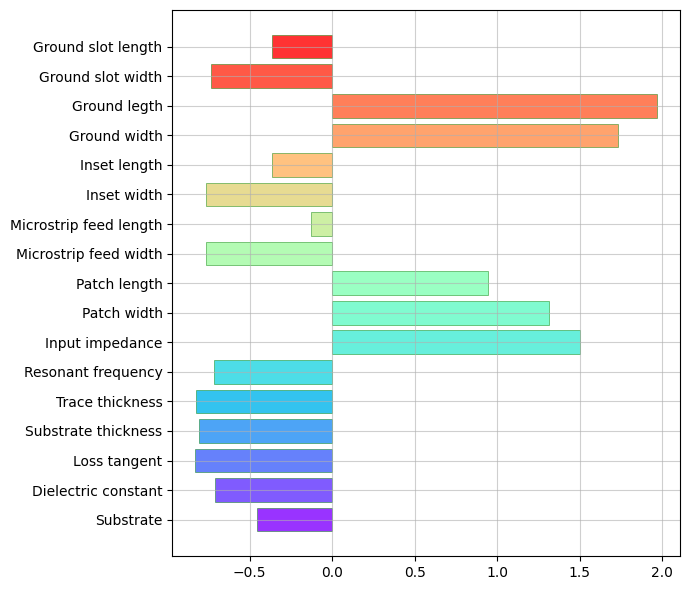

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import re
import warnings
warnings.filterwarnings('ignore')
# Read the CSV file
df = pd.read_csv('parameters.csv', header=None)

# Clean and process the data
df_clean = df.iloc[1:, 1:3]  # Select Parameters and Symbol columns
df_clean.columns = ['Parameter', 'Symbol']
df_clean['Value'] = df.iloc[1:, 3]

# Function to extract numeric values
def extract_numeric(value):
    if pd.isna(value):
        return np.nan
    value_str = str(value)
    # Remove units and extract number
    match = re.search(r'[-+]?\d*\.?\d+', value_str)
    if match:
        return float(match.group())
    return np.nan

# Extract numeric values
df_clean['Numeric_Value'] = df_clean['Value'].apply(extract_numeric)
df_clean = df_clean.dropna(subset=['Numeric_Value'])

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean['Numeric_Value'].values.reshape(-1, 1))

# Get parameters
parameters = df_clean['Parameter'].values
parameters = ["Substrate", "Dielectric constant", "Loss tangent", "Substrate thickness", "Trace thickness", "Resonant frequency", "Input impedance", "Patch width", "Patch length", "Microstrip feed width", "Microstrip feed length", "Inset width", "Inset length", "Ground width", "Ground legth","Ground slot width","Ground slot length"
]  # your custom labels

# Create the plot
plt.figure(figsize=(7,6))
colors = plt.cm.rainbow(np.linspace(0, 1, len(parameters)))
bars = plt.barh(parameters, X_scaled.flatten(), color=colors, alpha=0.8, edgecolor='green', linewidth=0.4)


plt.grid(True,alpha=0.6)
plt.tight_layout()
#plt.savefig('normalized parameters value.png',dpi=600)



In [ ]:
"Substrate", "Dielectric constant", "Loss tangent", "Substrate thickness", "Trace thickness", "Resonant frequency", "Input impedance", "Patch width", "Patch length", "Microstrip feed width", "Microstrip feed length", "Inset width", "Inset length", "Ground width", "Ground legth","Ground slot width","Ground slot length"
